# EMQA_L1_iran_brent

**Case study: Brent around the June 2025 Israel-Iran war**

Energy Markets Quantitative Analysis (EMQA), Lecture 1 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L1/EMQA_L1_iran_brent/EMQA_L1_iran_brent.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Brent front-month daily close from 2 June to 4 July 2025, with the Israeli strikes on Iran (13 June), the peak close and the ceasefire (24 June); prints the one-day jump, its size in 2024 standard deviations and the reversal.

**Data:** 2025-06-02 to 2025-07-04, trading days. **Source:** Yahoo Finance (BZ=F).

The numbers printed below are those on the slide; the tag `[key]` is their name in `lectures/L1/L1_numbers.json`.

In [2]:
import json
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per bidding zone
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZONES = ['RO', 'BG', 'HU', 'DE_LU']
ZONE_NAME = {'RO': 'Romania (OPCOM PZU)', 'BG': 'Bulgaria (IBEX)', 'HU': 'Hungary (HUPX)', 'DE_LU': 'Germany-Luxembourg'}
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
ZONE_SHORT = {'RO': 'RO (OPCOM PZU)', 'BG': 'BG (IBEX)', 'HU': 'HU (HUPX)', 'DE_LU': 'DE-LU (EPEX SPOT)'}


def month_ticks(ax, step=1):
    """Month axis 1..12: every month named, written vertically so it fits."""
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels([MON_EN[m - 1] if (m - 1) % step == 0 else '' for m in range(1, 13)], fontsize=9, rotation=90)


def legend_bottom(fig, ncol=4, y=0.0):
    """One legend centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l_ in zip(*ax.get_legend_handles_labels()):
            if l_ not in labels:
                handles.append(h)
                labels.append(l_)
    if handles:
        fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
                   handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Round as on the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')


def show(key, label, value):
    """Print a number of the slide; [key] = its name in lectures/L1/L1_numbers.json."""
    print(f'{label} = {value}   [{key}]')

## Data
Real series from the course repository (see `data/SOURCES.md`), cut at the last complete month; missing values stay missing.

In [3]:
# data cut-off: last complete calendar month common to the Romanian prices and the generation data
_p = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')['RO']
_g = pd.read_csv(DATA + 'generation_ro_mw_daily_cet.csv', usecols=['date_cet', 'hydro_run_of_river'],
                 parse_dates=['date_cet']).set_index('date_cet')['hydro_run_of_river']
_last = min(_p.dropna().index.max(), _g.dropna().index.max())
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
END_UTC = (END + pd.Timedelta(days=1)).tz_localize('Europe/Brussels').tz_convert('UTC')   # end of the CET day, in UTC
Y = END.year
print('data cut-off:', END.date())

# Brent front-month futures (Yahoo Finance BZ=F), daily close in USD/bbl
F = pd.read_csv(DATA + 'fuels_daily.csv', parse_dates=['date']).set_index('date').loc[:END]

data cut-off: 2026-10-31


## Computation

In [4]:
# Brent: the continuous front-month series switches contract on the first trading day of each month;
# that day's change mixes price and roll, so it is dropped from the return statistics
b = F['brent_usd_bbl'].dropna()
ROLL = b.groupby(b.index.to_period('M')).head(1).index
rb_all = np.log(b).diff().dropna() * 100                         # daily log returns, %
rb = rb_all.drop(rb_all.index.intersection(ROLL))                # roll days removed

p12, p13, p24 = (b.loc[x] for x in ['2025-06-12', '2025-06-13', '2025-06-24'])
win = b.loc['2025-06-13':'2025-06-23']
sd24 = rb.loc['2024'].std()                                     # daily return volatility in 2024, %
show('iran.p12', 'close 12 Jun 2025, USD/bbl', fl(p12, 2))
show('iran.p13', 'close 13 Jun 2025, USD/bbl', fl(p13, 2))
show('iran.chg13', 'change on 13 Jun, %', fl((p13 / p12 - 1) * 100, 1))
show('iran.z13', 'log change on 13 Jun / 2024 daily sd', fl(np.log(p13 / p12) * 100 / sd24, 1))
show('iran.peak', 'peak close 13-23 Jun, USD/bbl', fl(win.max(), 2))
show('iran.peak_date', 'date of the peak', d(win.idxmax()))
show('iran.p24', 'close 24 Jun 2025, USD/bbl', fl(p24, 2))
show('iran.chg24_peak', 'change peak -> 24 Jun, %', fl((p24 / win.max() - 1) * 100, 1))
show('iran.chg24_12', 'change 12 Jun -> 24 Jun, %', fl((p24 / p12 - 1) * 100, 1))

close 12 Jun 2025, USD/bbl = 69.36   [iran.p12]
close 13 Jun 2025, USD/bbl = 74.23   [iran.p13]
change on 13 Jun, % = 7.0   [iran.chg13]
log change on 13 Jun / 2024 daily sd = 4.3   [iran.z13]
peak close 13-23 Jun, USD/bbl = 77.01   [iran.peak]
date of the peak = 2025-06-20   [iran.peak_date]
close 24 Jun 2025, USD/bbl = 67.14   [iran.p24]
change peak -> 24 Jun, % = -12.8   [iran.chg24_peak]
change 12 Jun -> 24 Jun, % = -3.2   [iran.chg24_12]


## Chart

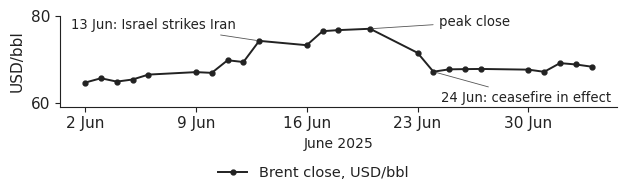

In [5]:
bw = b.loc['2025-06-02':'2025-07-04']
fig, ax = plt.subplots(figsize=(6.4, 2.0))
ax.plot(bw.index, bw, color='#222222', marker='o', ms=3.5, label='Brent close, USD/bbl')
# labels sit in free corners of the axes (axes fraction), with a thin leader line to their point
for dt, txt, xy_txt, ha in [('2025-06-13', '13 Jun: Israel strikes Iran', (0.02, 0.90), 'left'),
                            (str(win.idxmax().date()), 'peak close', (0.68, 0.93), 'left'),
                            ('2025-06-24', '24 Jun: ceasefire in effect', (0.99, 0.10), 'right')]:
    ax.annotate(txt, (pd.Timestamp(dt), b.loc[dt]), xytext=xy_txt, textcoords='axes fraction', ha=ha, va='center',
                fontsize=9.5, arrowprops=dict(arrowstyle='-', lw=0.6, color='#555555'))
ax.set_ylim(bw.min() - 5.5, bw.max() + 3)
ax.set_ylabel('USD/bbl')
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%-d %b'))
ax.set_xlabel(f'June {bw.index[0].year}', fontsize=10)
legend_bottom(fig, ncol=1)
fig.tight_layout(rect=(0, 0.13, 1, 1))
plt.savefig('iran_brent.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()